# 케이스별 monitor.csv 데이터 묶음

경로 리스트를 넣으면 `cases[이름]` = 구조화 배열(필드: `step, t, dt, div, Theta_c, Nu`) 묶음을 만든다.

- 경로는 런 디렉터리(`../e18_buoyfix_equil`) 또는 `monitor.csv` 파일 자체 둘 다 가능
- 재시작으로 step이 겹치면 마지막 기록만 남기고 step 순으로 정렬
- `Theta_c == 0` 구간은 stats 창이 아직 시작 안 된 구간 (필터는 시각화 쪽에서)

사용 예: `cases['e18_buoyfix_equil']['t']`, `cases['e18_buoyfix_equil']['Theta_c']`

In [16]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

def load_cases(paths, names=None):
    """paths: 런 디렉터리 또는 monitor.csv 경로 리스트.
    names: 각 경로에 붙일 이름 리스트(생략하면 디렉터리 이름).
    반환: {이름: 구조화 배열(step, t, dt, div, Theta_c, Nu)}"""
    cases = {}
    for i, p in enumerate(paths):
        p = Path(p)
        csv = p if p.suffix == '.csv' else p / 'monitor.csv'
        name = names[i] if names else (csv.parent.name if csv.parent.name != '.' else csv.stem)
        if not csv.exists():
            print(f'[skip] {csv} 없음')
            continue
        data = np.genfromtxt(csv, delimiter=',', names=True)
        data = data[np.argsort(data['step'], kind='stable')]
        keep = np.append(data['step'][1:] != data['step'][:-1], True)  # 겹친 step은 마지막 기록만
        data = data[keep]
        cases[name] = data
        print(f"{name:40s} rows={len(data):>7}  "
              f"step {data['step'][0]:.0f}..{data['step'][-1]:.0f}  "
              f"t {data['t'][0]:.1f}..{data['t'][-1]:.1f}  "
              f"Theta_c(last)={data['Theta_c'][-1]:.4f}")
    return cases

# Theta_c 유효 구간만 보려면: d = cases[name]; d = d[d['Theta_c'] != 0]
PaScaL_data = np.genfromtxt("PaScaL_TCS.csv", delimiter=",", comments="#")
Horm_data = np.genfromtxt("Horm.csv", delimiter=",", comments="#")
zhang_data = np.genfromtxt("zhang.csv", delimiter=",", comments="#")

256_0.3                                  rows=  16774  step 100..1677400  t 5.0..24999.2  Theta_c(last)=0.0694
dt(256_0.3) =  0.014901476602480028
Target_Theta = 20


Text(0, 0.5, '$\\theta_c$')

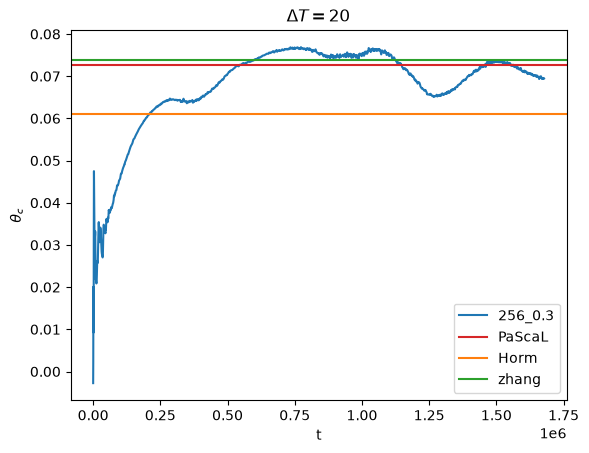

In [17]:
paths = [
    '../p8_deltat20_256_cold_cfl03',
]
names = [
    "256_0.3"
]
target = [
    20,
]

cases = load_cases(paths, names)

for i in range(len(paths)):

    plt.plot(cases[names[i]]["step"], cases[names[i]]["Theta_c"], label=names[i])
    print(f"dt({names[i]}) = ", np.mean(cases[names[i]]["dt"]))

print("Target_Theta =", target[0])
PaScaL_ref = np.interp(target[0], PaScaL_data[:, 0], PaScaL_data[:, 1])
Horm_ref = np.interp(target[0], Horm_data[:, 0], Horm_data[:, 1])
zhang_ref = np.interp(target[0], zhang_data[:, 0], zhang_data[:, 1])
plt.axhline(y=PaScaL_ref/target[0], color="tab:red", label="PaScaL")
plt.axhline(y=Horm_ref/target[0], color="tab:orange", label="Horm")
plt.axhline(y=zhang_ref/target[0], color="tab:green", label="zhang")
plt.legend()

plt.title(r"$\Delta{T} =$" + f"{target[0]}")
plt.xlabel("t")
plt.ylabel(r"$\theta_c$")

256_0.3_0                                rows=   5003  step 100..500300  t 5.0..12911.1  Theta_c(last)=0.1392
256_0.3_1                                rows=   4676  step 500100..967600  t 12905.9..24999.9  Theta_c(last)=0.1368
Target_Theta = 40


Text(0, 0.5, '$\\theta_c$')

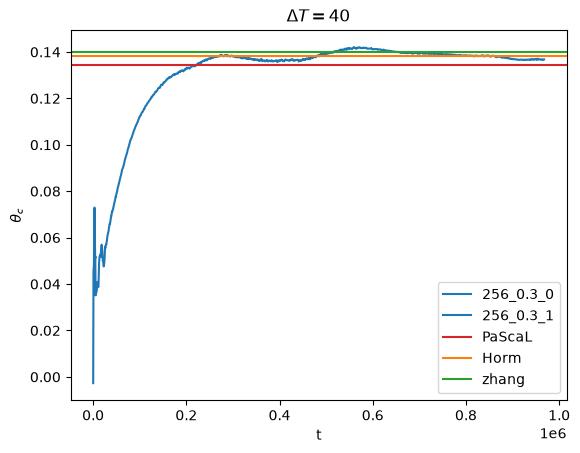

In [18]:
paths = [
    "../p7_deltat40_z256_cold_cfl03",
    "../p7b_deltat40_z256_resume",
]
names = [
    "256_0.3_0",
    "256_0.3_1",
]
target = [
    40,
    40,
]

cases = load_cases(paths, names)

for i in range(len(paths)):

    plt.plot(cases[names[i]]["step"], cases[names[i]]["Theta_c"], label=names[i], color="tab:blue")

print("Target_Theta =", target[0])
PaScaL_ref = np.interp(target[0], PaScaL_data[:, 0], PaScaL_data[:, 1])
Horm_ref = np.interp(target[0], Horm_data[:, 0], Horm_data[:, 1])
zhang_ref = np.interp(target[0], zhang_data[:, 0], zhang_data[:, 1])
plt.axhline(y=PaScaL_ref/target[0], color="tab:red", label="PaScaL")
plt.axhline(y=Horm_ref/target[0], color="tab:orange", label="Horm")
plt.axhline(y=zhang_ref/target[0], color="tab:green", label="zhang")
plt.legend()

plt.title(r"$\Delta{T} =$" + f"{target[0]}")
plt.xlabel("t")
plt.ylabel(r"$\theta_c$")
# plt.xlim(0, 8000)

256_0.3                                  rows=  13331  step 100..1333100  t 5.0..3587.9  Theta_c(last)=0.1722
dt(256_0.3) =  0.002690600429075089
Target_Theta = 60


Text(0, 0.5, '$\\theta_c$')

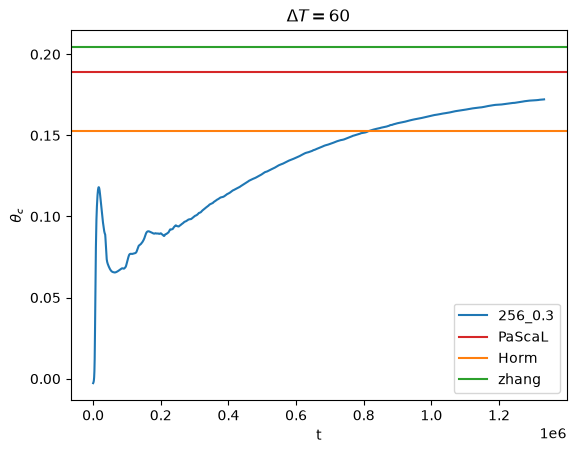

In [23]:
paths = [
    '../p9_deltat60_256_cold_cfl03',
]
names = [
    "256_0.3"
]
target = [
    60,
]

cases = load_cases(paths, names)

for i in range(len(paths)):

    plt.plot(cases[names[i]]["step"], cases[names[i]]["Theta_c"], label=names[i])
    print(f"dt({names[i]}) = ", np.mean(cases[names[i]]["dt"]))

print("Target_Theta =", target[0])
PaScaL_ref = np.interp(target[0], PaScaL_data[:, 0], PaScaL_data[:, 1])
Horm_ref = np.interp(target[0], Horm_data[:, 0], Horm_data[:, 1])
zhang_ref = np.interp(target[0], zhang_data[:, 0], zhang_data[:, 1])
plt.axhline(y=PaScaL_ref/target[0], color="tab:red", label="PaScaL")
plt.axhline(y=Horm_ref/target[0], color="tab:orange", label="Horm")
plt.axhline(y=zhang_ref/target[0], color="tab:green", label="zhang")
plt.legend()

plt.title(r"$\Delta{T} =$" + f"{target[0]}")
plt.xlabel("t")
plt.ylabel(r"$\theta_c$")

In [20]:
paths = [
    "../p8_deltat20_256_cold_cfl03",
    "../p7b_deltat40_z256_resume",
    "../p9_deltat60_256_cold_cfl03"
]
names = [
    "256_0.3",
    "256_0.3",
    "256_0.3"
]
target = [
    20,
    40,
    60
]

cases = load_cases(paths, names)

256_0.3                                  rows=  16774  step 100..1677400  t 5.0..24999.2  Theta_c(last)=0.0694
256_0.3                                  rows=   4676  step 500100..967600  t 12905.9..24999.9  Theta_c(last)=0.1368
256_0.3                                  rows=  13044  step 100..1304400  t 5.0..3510.6  Theta_c(last)=0.1716


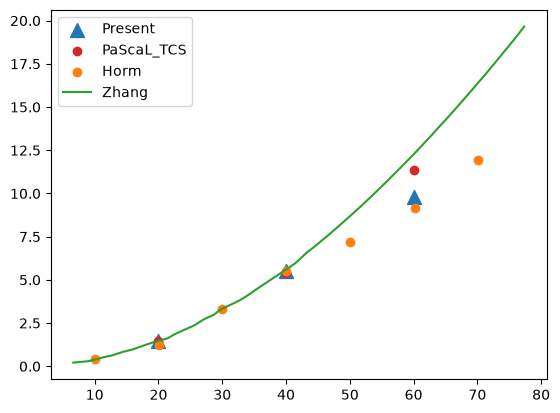

In [ ]:
l1 = []
for i in range(len(paths)):

    path = paths[i]

    data = np.loadtxt(f"{path}/stats_final.dat", delimiter=",")

    # 각 열 분리
    z      = data[:, 0]
    T_mean = data[:, 1]
    W_rms  = data[:, 2]

    T_results = np.interp(0.5, z, T_mean)
    l1.append(T_results * target[i])

plt.scatter(
    target,
    l1,
    s=100,                # 마커 크기
    marker="^",
    color="tab:blue",
    label="Present"
)

plt.scatter(PaScaL_data[:, 0], PaScaL_data[:, 1], label="PaScaL_TCS", color="tab:red")
plt.scatter(Horm_data[:, 0], Horm_data[:, 1], label="Horm", color="tab:orange")
plt.plot(zhang_data[:, 0], zhang_data[:, 1], label="Zhang", color="tab:green")
plt.legend()